# 07 · Pricing Tool: Fair Price Range and Deal Flags

**Goal:** turn the Random Forest into something a seller, a buyer or a marketplace could use, and measure how well
it would work:

1. **How close is the estimate?** Share of cars whose estimate is within 10%, 20% and 30% of the asking price.
2. **A fair price range instead of one number.** A single estimate is wrong by about \$3,500 on a new listing, so the
   tool should show a range that contains most real asking prices.
3. **Deal flags.** Listings priced below or above that range: possible bargains, data errors or over-priced cars.

The range is set on data the test set never touches (a validation split carved out of the training set, lessons 04
and 07), and the test set is used once to check it.

⏱️ *Runtime: about 5 minutes.*

In [1]:
import sys
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.pipeline import make_pipeline
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split

sys.path.append('../src')
from prep import (load_data, split, add_model_top, tree_preprocessor, linear_preprocessor,
                  near_twin_mask, NUM_COLS, RANDOM_STATE)

sns.set_theme(style='whitegrid')
df = load_data()
X_train, X_test, y_train, y_test = split(df)
X_train, X_test = add_model_top(X_train, X_test)

best = json.load(open('../results/best_params.json'))['Random Forest']
rf_params = {k.split('__')[1]: v for k, v in best.items()}
make_rf = lambda: make_pipeline(tree_preprocessor(), RandomForestRegressor(
    n_estimators=100, random_state=RANDOM_STATE, n_jobs=-1, **rf_params))

rf = make_rf().fit(X_train, np.log(y_train))
lr = make_pipeline(linear_preprocessor(), LinearRegression()).fit(X_train, np.log(y_train))

preds = pd.read_csv('../results/test_predictions.csv')
assert (preds['price'].values == y_test.values).all()
preds['Linear Regression'] = np.exp(lr.predict(X_test))
preds['Baseline (median price)'] = y_train.median()
preds['Random Forest'] = np.exp(rf.predict(X_test))
twin = near_twin_mask(X_train, X_test)
print(f'test cars: {len(preds):,} | with a near twin in training: {twin.mean():.1%}')

test cars: 41,529 | with a near twin in training: 25.7%


## 1. How close is the estimate?

For each car: `|estimate − asking price| / asking price`. The table shows the share of cars within 10%, 20% and 30%,
on all test cars and on the cars **without** a near twin in training (the fairer number for a brand-new listing,
see notebook 06).

In [2]:
pct_err = lambda name: (preds[name] - preds['price']).abs() / preds['price']
models = ['Baseline (median price)', 'Linear Regression', 'Gradient Boosting', 'Random Forest']
rows = []
for name in models:
    e = pct_err(name)
    for group, mask in [('all cars', np.ones(len(e), bool)), ('no near twin', ~twin)]:
        rows.append({'model': name, 'cars': group,
                     **{f'within {k}%': (e[mask] <= k / 100).mean() * 100 for k in (10, 20, 30)},
                     'median % error': e[mask].median() * 100})
accuracy = pd.DataFrame(rows).set_index(['model', 'cars']).round(1)
accuracy.to_csv('../results/pricing_accuracy.csv')
accuracy

within 10%  within 20%  within 30%  \
model                   cars                                               
Baseline (median price) all cars             8.7        16.3        25.6   
                        no near twin         8.3        15.9        25.1   
Linear Regression       all cars            26.8        50.7        68.7   
                        no near twin        25.6        48.6        66.2   
Gradient Boosting       all cars            33.3        59.2        75.7   
                        no near twin        31.9        56.8        73.7   
Random Forest           all cars            34.5        59.5        75.1   
                        no near twin        32.2        56.5        72.7   

                                      median % error  
model                   cars                          
Baseline (median price) all cars                55.7  
                        no near twin            56.5  
Linear Regression       all cars                19.6  
                        no near twin            20.7  
Gradient Boosting       all cars                16.0  
                        no near twin            16.9  
Random Forest           all cars                15.8  
                        no near twin            17.0

In [3]:
bands = pd.cut(preds['price'], [0, 5_000, 10_000, 20_000, 35_000, 150_000],
               labels=['< $5k', '$5-10k', '$10-20k', '$20-35k', '> $35k'])
e = pct_err('Random Forest')
by_band = pd.DataFrame({'cars': bands.value_counts(sort=False),
                        'within 10%': (e <= 0.10).groupby(bands, observed=True).mean() * 100,
                        'within 20%': (e <= 0.20).groupby(bands, observed=True).mean() * 100,
                        'median % error': e.groupby(bands, observed=True).median() * 100}).round(1)
by_band

,cars,within 10%,within 20%,median % error
price,,,,
< $5k,7852,21.7,39.2,28.2
$5-10k,10764,33.0,58.9,16.3
$10-20k,11877,38.5,65.5,13.8
$20-35k,7337,42.7,70.6,12.2
> $35k,3699,37.5,62.7,14.4


**How close the estimate is:**

- **Random Forest is within 20% of the asking price for 59.5% of cars** (56.5% of cars without a near twin), and within
  10% for about a third. Its median error is 15.8% of the price (17.0% on new listings).
- Linear Regression is within 20% for half of the cars; guessing the median price, for only 16%.
- On this measure **Random Forest and Gradient Boosting are equal** (59.5% vs 59.2% within 20%), which matches the
  near-twin finding in notebook 06.
- **By price:** cars between \$10,000 and \$35,000 are priced best (66–71% within 20%, median error 12–14%).
  **Cars under \$5,000 are the weak spot:** only 39% within 20%, median error 28%.

## 2. A fair price range

**How the range is built (no test data involved):**

1. Split the training set again: 80% to fit a Random Forest, 20% as a **validation set**.
2. On the validation cars, measure the error on the log scale: `log(asking price) − log(estimate)`.
3. Take its 10th and 90th percentiles. Because the model works on `log(price)`, they become **percentages** of the
   estimate, so the range is wider in dollars for expensive cars and narrower for cheap ones.
4. The tool shows `estimate × exp(p10)` to `estimate × exp(p90)`: in theory 80% of asking prices fall inside.

Then the test set checks whether about 80% of its cars really land inside the range.

80% range: estimate × 0.70 to estimate × 1.43  (-30% to +43%)
50% range: estimate × 0.86 to estimate × 1.18  (-14% to +18%)


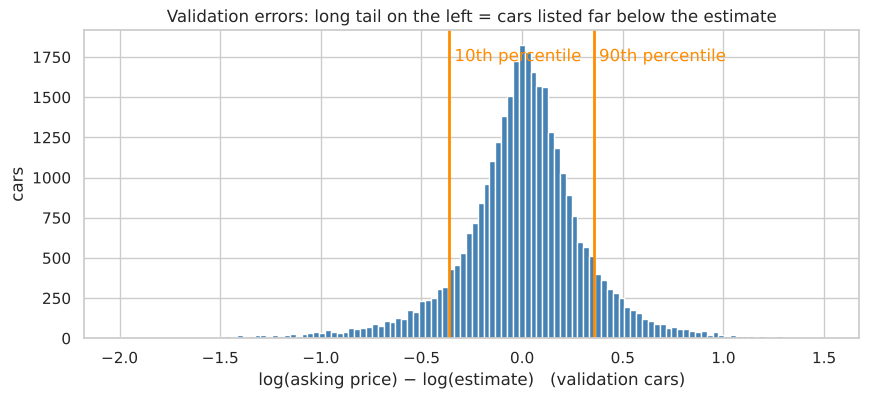

In [4]:
X_fit, X_val, y_fit, y_val = train_test_split(X_train, y_train, test_size=0.2, random_state=RANDOM_STATE)
X_fit, X_val = add_model_top(X_fit.drop(columns='model_top'), X_val.drop(columns='model_top'))
rf_val = make_rf().fit(X_fit, np.log(y_fit))
log_resid = np.log(y_val) - rf_val.predict(X_val)

p10, p90 = np.quantile(log_resid, [0.10, 0.90])
p25, p75 = np.quantile(log_resid, [0.25, 0.75])
price_range = {'p10': p10, 'p90': p90, 'p25': p25, 'p75': p75,
               'low_factor_80': np.exp(p10), 'high_factor_80': np.exp(p90)}
json.dump({k: round(float(v), 4) for k, v in price_range.items()}, open('../results/price_range.json', 'w'), indent=2)
print(f'80% range: estimate × {np.exp(p10):.2f} to estimate × {np.exp(p90):.2f}  '
      f'({(np.exp(p10) - 1) * 100:+.0f}% to {(np.exp(p90) - 1) * 100:+.0f}%)')
print(f'50% range: estimate × {np.exp(p25):.2f} to estimate × {np.exp(p75):.2f}  '
      f'({(np.exp(p25) - 1) * 100:+.0f}% to {(np.exp(p75) - 1) * 100:+.0f}%)')

fig, ax = plt.subplots(figsize=(10, 4))
ax.hist(log_resid, bins=120, range=(-2, 1.5), color='steelblue')
for q, lab in [(p10, '10th'), (p90, '90th')]:
    ax.axvline(q, color='darkorange', linewidth=2)
    ax.text(q, ax.get_ylim()[1] * 0.9, f' {lab} percentile', color='darkorange')
ax.set_xlabel('log(asking price) − log(estimate)   (validation cars)')
ax.set_ylabel('cars')
ax.set_title('Validation errors: long tail on the left = cars listed far below the estimate')
plt.show()

In [5]:
preds['low'] = preds['Random Forest'] * np.exp(p10)
preds['high'] = preds['Random Forest'] * np.exp(p90)
inside = (preds['price'] >= preds['low']) & (preds['price'] <= preds['high'])
print(f"Test cars inside the 80% range: {inside.mean():.1%} "
      f"(no near twin: {inside[~twin].mean():.1%})")
print(f"Below the range: {(preds['price'] < preds['low']).mean():.1%} | "
      f"above the range: {(preds['price'] > preds['high']).mean():.1%}")
width = preds['high'] - preds['low']
print(f"Median width of the range: ${width.median():,.0f}")

pd.DataFrame({'cars': bands.value_counts(sort=False),
              'inside range (%)': inside.groupby(bands, observed=True).mean() * 100,
              'below (%)': (preds['price'] < preds['low']).groupby(bands, observed=True).mean() * 100,
              'above (%)': (preds['price'] > preds['high']).groupby(bands, observed=True).mean() * 100,
              'median range': [f"${l:,.0f} – ${h:,.0f}" for l, h in zip(
                  preds['low'].groupby(bands, observed=True).median(),
                  preds['high'].groupby(bands, observed=True).median())]}).round(1)

Test cars inside the 80% range: 80.0% (no near twin: 77.8%)
Below the range: 9.9% | above the range: 10.1%
Median width of the range: $8,321


,cars,inside range (%),below (%),above (%),median range
price,,,,,
< $5k,7852,62.1,35.0,2.9,"$3,025 – $6,204"
$5-10k,10764,82.8,8.4,8.8,"$5,181 – $10,626"
$10-20k,11877,85.3,2.9,11.8,"$9,709 – $19,912"
$20-35k,7337,86.7,1.4,11.9,"$17,280 – $35,439"
> $35k,3699,79.5,0.1,20.4,"$27,312 – $56,014"


**The fair price range works as designed:**

- The 80% range is **estimate −30% to +43%**; the narrower 50% range is −14% to +18%. The range is lopsided
  because the errors have a long tail on the left: more cars are listed far *below* the estimate than far above it.
- **On the test set, exactly 80.0% of asking prices fall inside the range** (77.8% for cars without a near twin), with
  9.9% below and 10.1% above. The range was set without touching the test set, so this is a fair check.
- The typical range is about \$8,300 wide, for example \$9,700 – \$19,900 for a car estimated around \$14,000.
  That is honest, but wide: a range, not a precise price.
- **It does not fit every price band equally.** Under \$5,000 only 62% of cars land inside, and 35% are listed
  *below* the range (junk and parts cars, or prices that are not the full price). Above \$35,000, 20% are listed
  *above* the range (trims and options the data does not record). Between \$5,000 and \$35,000, 83–87% land inside.

## 3. Deal flags

Every test listing gets one of three labels:

- **Below the range:** asking price under the range. A possible bargain, or a listing with something the model does
  not see (damage, a wrong year or mileage, a down-payment price instead of the full price).
- **Fair:** inside the range.
- **Above the range:** asking price over the range. Possibly over-priced, or a car with extras the data does not show.

A flag means "worth a second look", not proof of a good or bad deal.

In [6]:
test = X_test.reset_index(drop=True).copy()
test['asking'] = preds['price']
test['estimate'] = preds['Random Forest'].round(-1)
test['low'], test['high'] = preds['low'].round(-1), preds['high'].round(-1)
test['flag'] = np.select([test['asking'] < test['low'], test['asking'] > test['high']],
                         ['below range', 'above range'], 'fair')
test['asking_vs_estimate_%'] = ((test['asking'] / test['estimate'] - 1) * 100).round(0)

counts = test['flag'].value_counts().reindex(['below range', 'fair', 'above range'])
print((counts / len(test) * 100).round(1).astype(str) + '%')

show = ['year', 'manufacturer', 'model', 'odometer', 'condition', 'title_status', 'asking', 'estimate',
        'low', 'high', 'asking_vs_estimate_%']
print('\nMost below the range:')
display(test.sort_values('asking_vs_estimate_%').head(8)[show])
print('Most above the range:')
display(test.sort_values('asking_vs_estimate_%', ascending=False).head(8)[show])

flag
below range     9.9%
fair           80.0%
above range    10.1%
Name: count, dtype: str

Most below the range:


,year,manufacturer,model,odometer,condition,title_status,asking,estimate,low,high,asking_vs_estimate_%
26384,2020,ford,f-350,15726.0,NaN,clean,1025,74130.0,51580.0,105780.0,-99.0
25401,2020,gmc,sierra 1500 denali,23396.0,NaN,clean,1030,75460.0,52510.0,107680.0,-99.0
972,2019,ram,2500,6130.0,NaN,clean,1116,68330.0,47540.0,97500.0,-98.0
33133,2020,ram,2500 laramie,136.0,excellent,NaN,1093,44770.0,31150.0,63880.0,-98.0
26642,2021,toyota,supra,10525.0,like new,clean,1000,47700.0,33190.0,68070.0,-98.0
462,2017,ford,super duty f-250 srw,18347.0,excellent,NaN,1055,43880.0,30530.0,62620.0,-98.0
8286,2019,rover,hse adap,26916.0,NaN,clean,1089,47620.0,33130.0,67950.0,-98.0
6341,2016,mercedes-benz,amg gt s carbon c,17046.0,NaN,clean,1051,38600.0,26850.0,55080.0,-97.0


Most above the range:


,year,manufacturer,model,odometer,condition,title_status,asking,estimate,low,high,asking_vs_estimate_%
37979,2009,volkswagen,gti,111111.0,NaN,salvage,111111,4890.0,3400.0,6980.0,2172.0
30098,2003,chevrolet,tahoe,165000.0,good,clean,123456,5460.0,3800.0,7790.0,2161.0
223,1991,NaN,All makes,400000.0,fair,clean,40000,2000.0,1390.0,2860.0,1900.0
37385,1993,ford,lightning,1918.0,NaN,clean,45500,2750.0,1910.0,3930.0,1555.0
367,2013,buick,lacrosse,94000.0,like new,lien,123456,9000.0,6260.0,12850.0,1272.0
1576,2021,NaN,Camaro mustang,1000.0,NaN,clean,100000,8080.0,5620.0,11540.0,1138.0
19662,2006,honda,odyssey ex-l,201000.0,good,clean,39000,3380.0,2350.0,4830.0,1054.0
10941,1997,chevrolet,camaro z28,2502.0,NaN,clean,35000,3170.0,2210.0,4520.0,1004.0


In [7]:
# What do flagged listings have in common? Signals of data problems or hidden damage
profile = test.assign(
    branded_title=test['title_status'].isin(['salvage', 'rebuilt', 'parts only', 'missing']),
    odometer_typo=(test['odometer'] <= 1_000) & (test['car_age'] >= 8),
    condition_missing=test['condition'].isna(),
    fair_or_salvage_condition=test['condition'].isin(['fair', 'salvage']),
).groupby('flag')[['branded_title', 'odometer_typo', 'condition_missing', 'fair_or_salvage_condition']].mean() * 100
profile['median age'] = test.groupby('flag')['car_age'].median()
profile['median asking'] = test.groupby('flag')['asking'].median()
profile.loc[['below range', 'fair', 'above range']].round(1)

,branded_title,odometer_typo,condition_missing,fair_or_salvage_condition,median age,median asking
flag,,,,,,
below range,7.4,1.1,36.3,6.6,13.0,3500.0
fair,3.7,0.5,38.1,1.6,8.0,12881.0
above range,3.4,0.9,38.6,4.8,13.0,16500.0


**What the flags catch:**

- **Below the range (9.9% of listings):** about two-thirds of them ask under \$5,000. Compared with fair listings
  they have twice the share of branded titles (salvage, rebuilt, parts only, missing: 7.4% vs 3.7%) and four times the
  share of "fair" or "salvage" condition (6.6% vs 1.6%), so many are damaged cars that are cheap for a reason. The
  most extreme cases are nearly new trucks listed around \$1,000 against estimates of \$40,000–75,000: almost
  certainly a down payment or a "call for price" placeholder, not the car's price.
- **Above the range (10.1%):** the extreme cases are fake prices such as \$111,111 and \$123,456, and 1990s
  collector cars (a 1993 Ford Lightning, a 1997 Camaro Z28 with 2,500 miles) that the model prices as ordinary old
  cars.
- So the flags are useful for **a marketplace's data-quality check** (placeholder prices, typos) as much as for
  finding bargains. A buyer should treat "below range" as "find out why".

## 4. The tool in use

`price_car()` takes a car's details, and returns the estimate and the 80% fair price range. Details the seller
leaves out are passed as missing, exactly like blank fields in the data.

In [8]:
TOP = set(X_train['model_top'].unique())

def price_car(**car):
    row = pd.DataFrame([car]).reindex(columns=X_train.columns)
    row['car_age'] = 2021 - row['year']
    row[NUM_COLS] = row[NUM_COLS].astype(float)
    row['model_top'] = row['model'].where(row['model'].isin(TOP), 'other')
    est = float(np.exp(rf.predict(row))[0])
    return {'estimate': round(est, -1), 'range_low': round(est * np.exp(p10), -1),
            'range_high': round(est * np.exp(p90), -1)}

examples = {
    '2015 Toyota Camry, 90k miles, gas, excellent': dict(
        year=2015, manufacturer='toyota', model='camry', odometer=90_000, fuel='gas', condition='excellent',
        cylinders_num=4, drive='fwd', type='sedan', transmission='automatic', title_status='clean', state='ca'),
    'same Camry with 150k miles': dict(
        year=2015, manufacturer='toyota', model='camry', odometer=150_000, fuel='gas', condition='excellent',
        cylinders_num=4, drive='fwd', type='sedan', transmission='automatic', title_status='clean', state='ca'),
    '2017 Ford F-250 diesel 4wd, 80k miles': dict(
        year=2017, manufacturer='ford', model='f-250', odometer=80_000, fuel='diesel', condition='good',
        cylinders_num=8, drive='4wd', type='pickup', transmission='automatic', title_status='clean', state='tx'),
    '2010 Honda Civic, 160k miles, few details given': dict(
        year=2010, manufacturer='honda', model='civic', odometer=160_000),
}
pd.DataFrame({k: price_car(**v) for k, v in examples.items()}).T

,estimate,range_low,range_high
"2015 Toyota Camry, 90k miles, gas, excellent",13380.0,9310.0,19100.0
same Camry with 150k miles,9210.0,6410.0,13140.0
"2017 Ford F-250 diesel 4wd, 80k miles",50830.0,35370.0,72540.0
"2010 Honda Civic, 160k miles, few details given",9140.0,6360.0,13040.0


**Reading the examples:**

- The 2015 Camry is estimated at \$13,380 (fair range \$9,310 – \$19,100). With 150,000 instead of 90,000 miles the
  estimate drops to \$9,210, about 31% less.
- The 2017 F-250 diesel 4wd is estimated at \$50,830: diesel, 4wd, 8 cylinders and a pickup body all push the price up.
- **A warning from the last example:** the 2010 Civic with 160,000 miles and no other details is estimated at
  \$9,140, almost the same as the five-years-newer Camry. Leaving fields blank sends them to the "unknown" levels,
  and in this data blank fields are common in dealer listings, which are pricier. A real tool should ask for
  condition, fuel, drive and type before showing a price.

## Summary

| Question | Answer (test set) |
| --- | --- |
| Estimate within 20% of the asking price | 59.5% of cars (56.5% of new listings); Linear Regression 50.7%, median guess 16.3% |
| Median error | 15.8% of the price (17.0% on new listings) |
| 80% fair price range | estimate −30% to +43%; **80.0% of test cars fall inside** |
| Best price band | \$10,000 – \$35,000: 85–87% inside the range |
| Weakest band | under \$5,000: 62% inside, 35% listed below the range |
| Flagged listings | 9.9% below, 10.1% above the range |

**What this means for each audience:**

- **Sellers:** price inside the range, nearer the estimate for a typical car. Pricing above the range puts a listing among
  the 10% that the tool would flag as over-priced.
- **Buyers:** a car listed below the range is worth a look, but first check the title, the condition and whether the
  price is the full price.
- **Marketplaces:** a "fair price" badge is supported for cars between \$5,000 and \$35,000. The flags also catch
  placeholder prices (\$1,000 down payments, \$123,456) that could be checked automatically.

**Limits:** the range is wide (−30% to +43%), because the data has no trim, options or accident history; the tool
needs the main details filled in; and it reflects April–May 2021 asking prices.

Saved: `results/pricing_accuracy.csv`, `results/price_range.json`.

**Next:** stage 13: final results and recommendations (`docs/05_results_and_recommendations.md`).